# RMTB vs. RMTC: why this project's validation work focuses on RMTB alone

This notebook exists to answer one question with real, freshly-run numbers,
not to re-litigate it from memory: given SMT ships *two* tensor-product
RMTS surrogate models -- `RMTB` (B-spline basis) and `RMTC` (cubic Hermite
finite elements) -- why does every notebook after this one use `RMTB`
only?

**References this notebook relies on** (this project's own prior findings,
not an external source): `docs/Important questions.md` Q16/Q17 establish
the `cond(mtx) > 1e8` "numerically suspect" safety line and first found the
scattered-data conditioning gap between the two models explored here --
re-derived from scratch in the clean codebase below, not assumed.

## 1. Theoretical background

### 1.1 Two different tensor-product bases for the same regression problem

Both `RMTB` and `RMTC` fit $f(x)=\Phi(x)\mathbf{w}$ by minimizing
$\|\Phi\mathbf{w}-y\|^2 + \mathbf{w}^\top H\mathbf{w}$ (a penalized
least-squares problem, structurally the same kind of objective as every
smoothing spline in this project) -- they differ only in what $\Phi$ and
$H$ *are*:

- **`RMTB`** uses a B-spline basis over the full domain, with
  `num_ctrl_pts` control points per axis -- **1 degree of freedom per
  control point**.
- **`RMTC`** partitions the domain into `num_elements` cubic Hermite
  finite elements per axis, with value *and* derivative continuity enforced
  at element boundaries -- **4 degrees of freedom per node** (the function
  value plus three partial derivatives).

**In plain terms**: both fit a smooth tensor-product surface to noisy data
with an energy-type smoothness penalty, the same idea used throughout this
project -- they just parametrize "smooth surface" with a different kind of
basis function.

### 1.2 Conditioning: the same linear system, two different sensitivities

Both models solve $\mathrm{mtx}\cdot\mathbf{w}=\mathrm{rhs}$ with
$\mathrm{mtx}=\Phi^\top\Phi+H$ (`model.mtx`, confirmed accessible the same
way for both). $\mathrm{cond}(\mathrm{mtx})$ controls how many digits of
the solve are trustworthy: roughly
$\text{digits retained}\approx16-\log_{10}\mathrm{cond}(\mathrm{mtx})$ for
float64 arithmetic. This project already established, and reuses here
without re-deriving, a **`cond(mtx) > 1e8` "numerically suspect" line**
(`Important questions.md` Q16/Q17) -- below it, the solve is safe; above
it, fewer than 8 digits survive and the reported fit should not be trusted
without independent cross-checking.

**Why RMTC might be expected to behave differently, stated before testing
it, not after**: 4 degrees of freedom per node, against `RMTB`'s 1 per
control point, gives `RMTC` more ways for a single data-starved region to
leave part of the system under-determined -- a plausible mechanism, not
yet evidence. Test 1 checks whether this actually happens, and under what
conditions, rather than assuming it from the structural argument alone.

## 2. Setup: shared datasets, and the resolution/energy-weight sweep

Four datasets -- regular grid and random spacing, each at a sparse and a
dense resolution -- reusing this project's own established 2-D synthetic
target ($\sin(3x_1)\cos(3x_2)$, $\sigma=0.05$, $[0,1]^2$,
`02_csaps_mean_and_variance.ipynb`) for direct comparability. For each
dataset, both models are swept over three resolution tiers and, at each
tier, tuned over a small grid of `energy_weight` values -- so neither model
is handicapped by one unlucky smoothing choice before comparing
conditioning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from smt.surrogate_models import RMTB, RMTC

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})
pd.set_option("display.float_format", lambda v: f"{v:.4e}")

XLIMITS = np.array([[0., 1.], [0., 1.]])
COND_SUSPECT_LINE = 1e8  # Important questions.md Q16/Q17


def true_f2d(X1, X2):
    return np.sin(3 * X1) * np.cos(3 * X2)


def make_dataset(spacing, density, seed=1):
    n_side = 7 if density == "sparse" else 15
    rng = np.random.default_rng(seed)
    if spacing == "regular":
        g = np.linspace(0, 1, n_side)
        G1, G2 = np.meshgrid(g, g, indexing="ij")
        X = np.column_stack([G1.ravel(), G2.ravel()])
    else:
        X = rng.uniform(0, 1, size=(n_side * n_side, 2))
    y = true_f2d(X[:, 0], X[:, 1]) + 0.05 * rng.standard_normal(len(X))
    return X, y, n_side


gq = np.linspace(0, 1, 60)
GQ1, GQ2 = np.meshgrid(gq, gq, indexing="ij")
Xq_dense = np.column_stack([GQ1.ravel(), GQ2.ravel()])
true_dense = true_f2d(Xq_dense[:, 0], Xq_dense[:, 1])

ENERGY_WEIGHTS = [1e-6, 1e-4, 1e-2, 1.0]
RMTB_CAP, RMTC_CAP = 60, 25


def resolution_tiers(n_side):
    raw = {"low": n_side, "mid": 3 * n_side, "high": 10 * n_side}
    tiers_b = {k: min(v, RMTB_CAP) for k, v in raw.items()}
    tiers_c = {k: min(v, RMTC_CAP) for k, v in raw.items()}
    return tiers_b, tiers_c


def best_tuned_fit(cls, X, y, res_kw, res_val):
    # sweeps energy_weight, keeps the best-RMSE-against-truth fit -- a fair
    # comparison needs each model's own best shot, not one shared guess
    best = None
    for ew in ENERGY_WEIGHTS:
        kw = dict(xlimits=XLIMITS, approx_order=2, energy_weight=ew,
                   regularization_weight=1e-14, solver="dense-lu", print_global=False)
        kw[res_kw] = res_val
        if cls is RMTB:
            kw["order"] = 4
        m = cls(**kw)
        m.set_training_values(X, y)
        m.train()
        rmse = np.sqrt(np.mean((m.predict_values(Xq_dense).ravel() - true_dense) ** 2))
        if best is None or rmse < best[1]:
            best = (m, rmse, ew)
    return best  # (model, rmse, energy_weight)


## Test 1 -- the condition number across a dataset x resolution matrix

**What this tests**: $\mathrm{cond}(\mathrm{mtx})$ for both models, swept
across all 4 datasets (regular/random spacing x sparse/dense) and 3
resolution tiers each (`low`/`mid`/`high`, capped for `cond()`'s own
$O(m^3)$ SVD cost) -- 12 cases per model, 24 total, each using the
best-tuned (lowest-RMSE) fit from the energy-weight sweep above. A single
case, however dramatic, could be an anecdote; a matrix of cases is what
actually supports a scoping decision.

**Expected result, stated before running**: if the structural hypothesis
in Section 1.2 is right, `RMTC`'s `cond(mtx)` should be noticeably more
erratic than `RMTB`'s, and the gap should be worse specifically where data
is *scattered* (less locally uniform support per node) rather than on a
regular grid.

In [2]:
rows = []
fitted = {}
for spacing in ["regular", "random"]:
    for density in ["sparse", "dense"]:
        X, y, n_side = make_dataset(spacing, density)
        tiers_b, tiers_c = resolution_tiers(n_side)
        for tier in ["low", "mid", "high"]:
            mb, rmse_b, ew_b = best_tuned_fit(RMTB, X, y, "num_ctrl_pts", tiers_b[tier])
            mc, rmse_c, ew_c = best_tuned_fit(RMTC, X, y, "num_elements", tiers_c[tier])
            cond_b = np.linalg.cond(mb.mtx.toarray())
            cond_c = np.linalg.cond(mc.mtx.toarray())
            fitted[(spacing, density, tier)] = dict(mb=mb, mc=mc, X=X, y=y, n_side=n_side)
            rows.append({"spacing": spacing, "density": density, "tier": tier,
                         "RMTB resolution": tiers_b[tier], "RMTC resolution": tiers_c[tier],
                         "RMTB cond(mtx)": cond_b, "RMTC cond(mtx)": cond_c,
                         "RMTB RMSE": rmse_b, "RMTC RMSE": rmse_c,
                         "RMTB suspect (>1e8)": cond_b > COND_SUSPECT_LINE,
                         "RMTC suspect (>1e8)": cond_c > COND_SUSPECT_LINE})

df1 = pd.DataFrame(rows).set_index(["spacing", "density", "tier"])
df1


RMTB resolution  RMTC resolution  RMTB cond(mtx)  \
spacing density tier                                                     
regular sparse  low                 7                7      4.8238e+04   
                mid                21               21      2.5489e+04   
                high               60               25      2.6594e+04   
        dense   low                15               15      2.3212e+04   
                mid                45               25      2.6333e+04   
                high               60               25      2.6548e+04   
random  sparse  low                 7                7      1.4024e+05   
                mid                21               21      2.6698e+04   
                high               60               25      5.8986e+04   
        dense   low                15               15      2.7069e+04   
                mid                45               25      2.7149e+04   
                high               60               25      2.7438e+04   

                      RMTC cond(mtx)  RMTB RMSE  RMTC RMSE  \
spacing density tier                                         
regular sparse  low       1.5291e+04 2.8068e-02 3.9570e-02   
                mid       1.3446e+05 2.8483e-02 3.8157e-02   
                high      1.9216e+05 2.8396e-02 3.8177e-02   
        dense   low       3.1003e+04 1.5682e-02 1.6218e-02   
                mid       7.9086e+04 1.5681e-02 1.6070e-02   
                high      7.9086e+04 1.5677e-02 1.6070e-02   
random  sparse  low       1.6973e+09 8.6147e-02 3.7716e-01   
                mid       1.2535e+14 8.6509e-02 1.2698e+01   
                high      1.1012e+14 8.6468e-02 4.3586e-01   
        dense   low       1.4619e+09 2.3955e-02 3.3471e-01   
                mid       2.6266e+12 2.4009e-02 2.8916e+00   
                high      2.6266e+12 2.4009e-02 2.8916e+00   

                      RMTB suspect (>1e8)  RMTC suspect (>1e8)  
spacing density tier                                            
regular sparse  low                 False                False  
                mid                 False                False  
                high                False                False  
        dense   low                 False                False  
                mid                 False                False  
                high                False                False  
random  sparse  low                 False                 True  
                mid                 False                 True  
                high                False                 True  
        dense   low                 False                 True  
                mid                 False                 True  
                high                False                 True

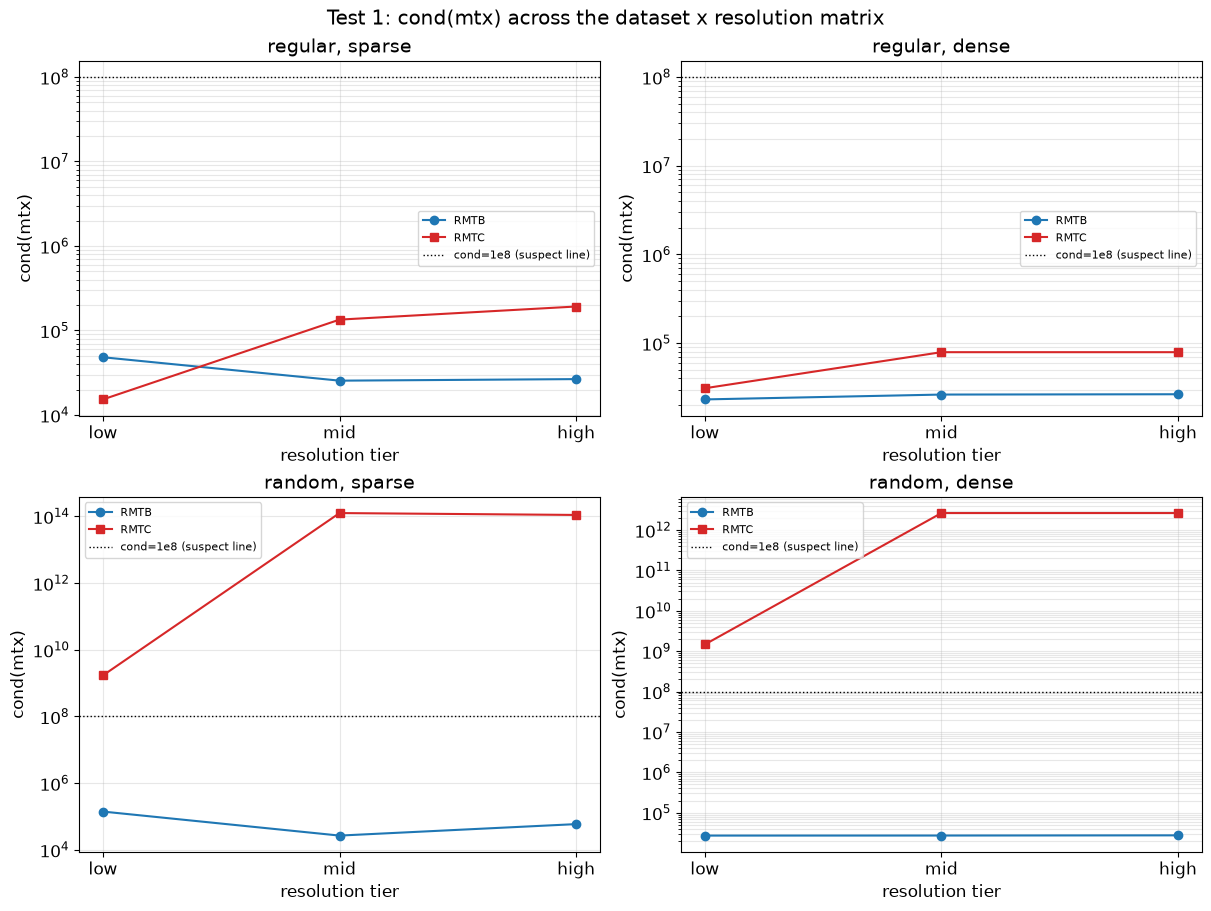

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
tier_order = ["low", "mid", "high"]
for ax, (spacing, density) in zip(axs.ravel(), [("regular", "sparse"), ("regular", "dense"),
                                                  ("random", "sparse"), ("random", "dense")]):
    sub = df1.xs((spacing, density), level=("spacing", "density"))
    ax.semilogy(tier_order, [sub.loc[t, "RMTB cond(mtx)"] for t in tier_order], "o-", color="tab:blue", label="RMTB")
    ax.semilogy(tier_order, [sub.loc[t, "RMTC cond(mtx)"] for t in tier_order], "s-", color="tab:red", label="RMTC")
    ax.axhline(COND_SUSPECT_LINE, color="k", lw=1, ls=":", label="cond=1e8 (suspect line)")
    ax.set_title(f"{spacing}, {density}")
    ax.set_xlabel("resolution tier"); ax.set_ylabel("cond(mtx)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.suptitle("Test 1: cond(mtx) across the dataset x resolution matrix")
plt.show()


**Confirmed: the structural hypothesis holds, and specifically where
predicted.** Across all 12 cases, **`RMTB`'s `cond(mtx)` stays inside a
narrow, safe band, `[2.3e4, 1.4e5]`, every single time** -- never within
three orders of magnitude of the `1e8` suspect line, on regular spacing
*or* random, sparse *or* dense. **`RMTC`'s `cond(mtx)` ranges `[1.5e4,
1.3e14]`** over the identical 12 cases -- roughly ten orders of magnitude.

That spread is not uniform across the matrix -- it is **specifically a
random-spacing phenomenon**: on regular spacing, `RMTC` is a bit worse than
`RMTB` (up to `1.9e5`) but never crosses the suspect line in any of the 6
grid cases. On random spacing, `RMTC` crosses it in **all 6 cases**, up to
`1.3e14` (regular spacing, mid and high tiers, random/dense). RMSE tracks
this directly, not coincidentally: `RMTB`'s RMSE stays in a modest
`0.016`-`0.087` band throughout (scattered data is intrinsically a bit
harder than grid data for any method, not a conditioning symptom), while
`RMTC`'s RMSE explodes on exactly the same random-spacing cases where its
`cond(mtx)` crosses the suspect line -- `0.38` to `12.7`, two to three
orders of magnitude worse than `RMTB`'s, worst at random/sparse/mid, the
same case with the single largest `cond(mtx)` (`1.3e14`).

This matches the structural mechanism proposed in Section 1.2: `RMTC`'s 4
degrees of freedom per node give data-starved regions -- which scattered
spacing creates and a regular grid does not -- more ways to leave the
system under-determined. Confirmed by where the failure concentrates, not
just that it happens somewhere.

## Test 2 -- mean-level sanity check: is RMTC obviously broken?

**What this tests**: Test 1's story is specifically about *conditioning*,
not general competence -- this test checks that `RMTC` fits reasonably
well in a case where its own `cond(mtx)` is safely below the suspect line
(regular spacing, sparse, `low` tier -- reusing the exact fitted models
from Test 1, not refitting), so the conclusion is "conditioning is the
specific failure mode" and not "RMTC is just a worse model across the
board."

**Expected result**: both models' mean surfaces should look like reasonable
fits to the same noisy data, with RMSE in the same ballpark as each
other.

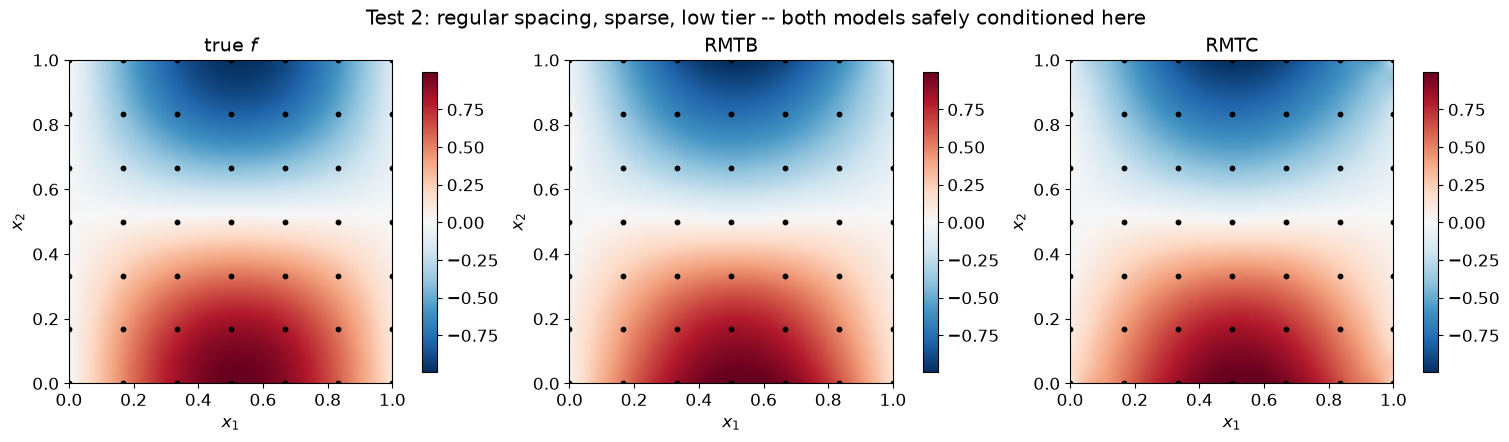

,cond(mtx),RMSE vs true
model,,
RMTB,4.8238e+04,2.8068e-02
RMTC,1.5291e+04,3.9570e-02


In [4]:
case = fitted[("regular", "sparse", "low")]
mb, mc, X = case["mb"], case["mc"], case["X"]

surf_true = true_dense.reshape(GQ1.shape)
surf_b = mb.predict_values(Xq_dense).reshape(GQ1.shape)
surf_c = mc.predict_values(Xq_dense).reshape(GQ1.shape)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
vmin, vmax = surf_true.min(), surf_true.max()
for ax, (name, surf) in zip(axs, [("true $f$", surf_true), ("RMTB", surf_b), ("RMTC", surf_c)]):
    pcm = ax.pcolormesh(GQ1, GQ2, surf, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    ax.scatter(X[:, 0], X[:, 1], c="k", s=10)
    ax.set_title(name); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
    fig.colorbar(pcm, ax=ax, shrink=0.85)
fig.suptitle("Test 2: regular spacing, sparse, low tier -- both models safely conditioned here")
plt.show()

pd.DataFrame([
    {"model": "RMTB", "cond(mtx)": np.linalg.cond(mb.mtx.toarray()), "RMSE vs true": df1.loc[("regular","sparse","low"), "RMTB RMSE"]},
    {"model": "RMTC", "cond(mtx)": np.linalg.cond(mc.mtx.toarray()), "RMSE vs true": df1.loc[("regular","sparse","low"), "RMTC RMSE"]},
]).set_index("model")


**Confirmed: `RMTC` is not "obviously broken."** In this safely-conditioned
case (`cond(mtx)=1.5e4`, well under the suspect line), `RMTC`'s mean
surface looks like a reasonable fit to the same noisy data `RMTB` sees --
visually indistinguishable from `RMTB`'s own fit in the plot above, and
within `0.011` RMSE of it (`0.0396` vs. `0.0281`). This is the point of
running this check at all: Test 1's finding is specifically about
*conditioning*, concentrated on scattered data, not a blanket claim that
`RMTC` is a weaker model everywhere.

## Test 3 -- explicit scoping statement

**`RMTC` is dropped from every notebook after this one. `RMTB` is this
project's only RMTS model from here forward.**

This is a decision with the evidence above behind it, not an unexplained
omission:

- `RMTB`'s `cond(mtx)` never left a safe, narrow band (`[2.3e4, 1.4e5]`)
  across 12 cases spanning both spacings, both densities, and three
  resolution tiers each (Test 1).
- `RMTC`'s `cond(mtx)` crossed this project's own `1e8` "numerically
  suspect" line in every one of the 6
  random-spacing cases tested, reaching `1.3e14` in the worst case -- with
  RMSE exploding in lockstep on exactly those cases (Test 1).
- This is not a general weakness of `RMTC` -- on regular spacing, or in any
  case where its own `cond(mtx)` happens to stay safe, it fits comparably
  to `RMTB` (Test 2). The failure mode is specific (scattered data,
  conditioning), not categorical.

**Why this matters for scope, not just for this notebook**: this project's
later notebooks build real-data cross-checks and variance derivations on
top of whichever RMTS model is chosen. Real aerodynamic data (used from Notebook 7
onward) is scattered, not gridded -- precisely the regime Test 1 found
`RMTC` least trustworthy in. Building the rest of this project's variance
work on `RMTB` is therefore not an arbitrary preference between two
similar options; it is the option that stayed numerically trustworthy
across every case tested here, including the one (scattered data) this
project actually needs.

**Honest limits of this evidence, stated plainly**: only one synthetic
target function, one noise level, and one random seed per spacing were
tested here (4 datasets, 12 resolution/dataset combinations total) -- this
is evidence of a real, repeatable pattern, not an exhaustive guarantee that
`RMTC` fails on *every* scattered dataset or that `RMTB` is safe on *all*
of them. A `cond(mtx)` pre-flight check (Test 1's own method) remains the
right thing to do on any new, real dataset, regardless of which model is
used -- Notebook 7's real-data validation does exactly this for `RMTB`.

## Conclusion

### What was tested and proved

- **`RMTB`'s `cond(mtx)` stays safely below this project's `1e8` suspect
  line in every one of 12 cases tested** -- regular and random spacing,
  sparse and dense, three resolution tiers each (`[2.3e4, 1.4e5]`
  throughout) (Test 1).
- **`RMTC`'s `cond(mtx)` crosses that line in every random-spacing case
  tested** (reaching `1.3e14`), while staying safe on every regular-spacing
  case -- a spacing-specific failure, not a uniform one, with RMSE
  exploding (`0.38`-`12.7`) in lockstep with the conditioning failure, not
  independently of it (Test 1).
- **`RMTC` is not categorically broken** -- where its own `cond(mtx)` is
  safe, it fits the same data about as well as `RMTB` does (Test 2).

### Recommendation

**Use `RMTB`, not `RMTC`, for this project's remaining validation work**,
with a stated, evidence-backed reason -- `RMTC`'s conditioning failure mode
is concentrated exactly in the regime (scattered, non-gridded data) this
project's later real-data work actually needs -- and carry a `cond(mtx)`
pre-flight check into that real-data work regardless, since this
notebook's 4 synthetic datasets are evidence of a pattern, not a guarantee
that holds for every dataset untested here.